# Лабораторная работа №1: метод обратного распространения ошибки

In [15]:
from pathlib import Path
import gzip
import struct
import time
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)

In [16]:
BASE_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
FILES = {
    "train_images": "train-images-idx3-ubyte.gz",
    "train_labels": "train-labels-idx1-ubyte.gz",
    "test_images": "t10k-images-idx3-ubyte.gz",
    "test_labels": "t10k-labels-idx1-ubyte.gz",
}
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

for filename in FILES.values():
    path = DATA_DIR / filename
    if not path.exists():
        urlretrieve(BASE_URL + filename, path)

def read_images(path):
    with gzip.open(path, "rb") as file:
        _, count, rows, cols = struct.unpack(">4I", file.read(16))
        pixels = np.frombuffer(file.read(), dtype=np.uint8)

    return pixels.reshape(count, rows, cols)


def read_labels(path):
    with gzip.open(path, "rb") as file:
        file.read(8)
        return np.frombuffer(file.read(), dtype=np.uint8)

X_train_images = read_images(DATA_DIR / FILES["train_images"])
y_train = read_labels(DATA_DIR / FILES["train_labels"])
X_test_images = read_images(DATA_DIR / FILES["test_images"])
y_test = read_labels(DATA_DIR / FILES["test_labels"])

X_train = X_train_images.reshape(len(X_train_images), -1).astype(np.float32) / 255.0
X_test = X_test_images.reshape(len(X_test_images), -1).astype(np.float32) / 255.0

print(f"Обучающая выборка: {X_train_images.shape}, метки {y_train.shape}")
print(f"Тестовая выборка: {X_test_images.shape}, метки {y_test.shape}")
print(f"Форма изображения: {X_train_images[0].shape}")

Обучающая выборка: (60000, 28, 28), метки (60000,)
Тестовая выборка: (10000, 28, 28), метки (10000,)
Форма изображения: (28, 28)


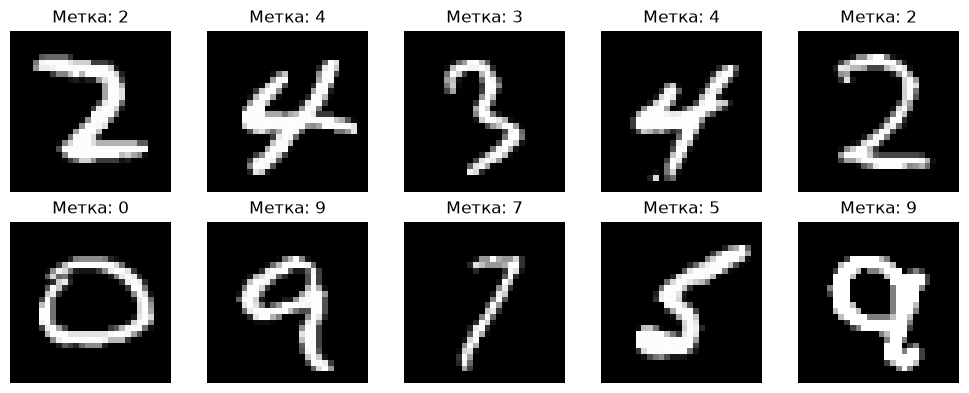

In [17]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
indices = rng.choice(len(X_train_images), size=10, replace=False)
for ax, index in zip(axes.ravel(), indices):
    ax.imshow(X_train_images[index], cmap="gray")
    ax.set_title(f"Метка: {y_train[index]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [18]:
class TwoLayerNet:
    def __init__(self, input_size, hidden_size, output_size, seed=42):
        generator = np.random.default_rng(seed)
        self.params = {
            "W1": (generator.standard_normal((input_size, hidden_size))
                   * np.sqrt(2.0 / input_size)).astype(np.float32),
            "b1": np.zeros((1, hidden_size), dtype=np.float32),
            "W2": (generator.standard_normal((hidden_size, output_size))
                   * np.sqrt(2.0 / hidden_size)).astype(np.float32),
            "b2": np.zeros((1, output_size), dtype=np.float32),
        }

    def forward(self, X):
        z1 = X @ self.params["W1"] + self.params["b1"]
        a1 = np.maximum(z1, 0.0)
        z2 = a1 @ self.params["W2"] + self.params["b2"]
        shifted = z2 - z2.max(axis=1, keepdims=True)
        exp_scores = np.exp(shifted)
        probabilities = exp_scores / exp_scores.sum(axis=1, keepdims=True)
        return probabilities, (X, z1, a1, probabilities)

    @staticmethod
    def cross_entropy(probabilities, targets):
        selected = probabilities[np.arange(len(targets)), targets]
        return float(-np.log(np.clip(selected, 1e-12, 1.0)).mean())

    def backward(self, cache, targets):
        X, z1, a1, probabilities = cache
        batch_size = X.shape[0]
        dz2 = probabilities.copy()
        dz2[np.arange(batch_size), targets] -= 1.0
        dz2 /= batch_size
        dW2 = a1.T @ dz2
        db2 = dz2.sum(axis=0, keepdims=True)
        dz1 = (dz2 @ self.params["W2"].T) * (z1 > 0.0)
        dW1 = X.T @ dz1
        db1 = dz1.sum(axis=0, keepdims=True)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def step(self, gradients, learning_rate):
        for name in self.params:
            self.params[name] -= learning_rate * gradients[name]

    def predict(self, X, batch_size=64):
        parts = []
        for start in range(0, len(X), batch_size):
            probabilities, _ = self.forward(X[start:start + batch_size])
            parts.append(probabilities.argmax(axis=1))
        return np.concatenate(parts)

    def accuracy(self, X, y):
        return float(np.mean(self.predict(X) == y))

In [19]:
HIDDEN_SIZE = 300
LEARNING_RATE = 0.1
BATCH_SIZE = 64
EPOCHS = 20

model = TwoLayerNet(X_train.shape[1], HIDDEN_SIZE, 10, seed=SEED)
history = {"loss": [], "train_accuracy": [], "epoch_time": []}
train_rng = np.random.default_rng(SEED)

training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    permutation = train_rng.permutation(len(X_train))
    loss_sum = 0.0
    examples_seen = 0

    for start in range(0, len(X_train), BATCH_SIZE):
        batch_indices = permutation[start:start + BATCH_SIZE]
        X_batch = X_train[batch_indices]
        y_batch = y_train[batch_indices]
        probabilities, cache = model.forward(X_batch)
        batch_loss = model.cross_entropy(probabilities, y_batch)
        gradients = model.backward(cache, y_batch)
        model.step(gradients, LEARNING_RATE)
        loss_sum += batch_loss * len(X_batch)
        examples_seen += len(X_batch)

    epoch_loss = loss_sum / examples_seen
    train_accuracy = model.accuracy(X_train, y_train)
    elapsed = time.perf_counter() - epoch_start
    history["loss"].append(epoch_loss)
    history["train_accuracy"].append(train_accuracy)
    history["epoch_time"].append(elapsed)
    print(f"Эпоха {epoch}/{EPOCHS}: ошибка на train={1 - train_accuracy:.2%}, "
          f"время={elapsed:.1f} с")

Эпоха 1/20: ошибка на train=6.08%, время=1.1 с
Эпоха 2/20: ошибка на train=4.29%, время=0.6 с
Эпоха 3/20: ошибка на train=3.24%, время=0.5 с
Эпоха 4/20: ошибка на train=2.57%, время=0.6 с
Эпоха 5/20: ошибка на train=2.20%, время=0.5 с
Эпоха 6/20: ошибка на train=1.85%, время=0.6 с
Эпоха 7/20: ошибка на train=1.68%, время=0.7 с
Эпоха 8/20: ошибка на train=1.31%, время=0.5 с
Эпоха 9/20: ошибка на train=1.15%, время=0.8 с
Эпоха 10/20: ошибка на train=1.02%, время=0.6 с
Эпоха 11/20: ошибка на train=0.91%, время=0.6 с
Эпоха 12/20: ошибка на train=0.79%, время=0.6 с
Эпоха 13/20: ошибка на train=0.70%, время=0.5 с
Эпоха 14/20: ошибка на train=0.59%, время=0.5 с
Эпоха 15/20: ошибка на train=0.56%, время=0.5 с
Эпоха 16/20: ошибка на train=0.45%, время=0.5 с
Эпоха 17/20: ошибка на train=0.33%, время=0.5 с
Эпоха 18/20: ошибка на train=0.34%, время=0.5 с
Эпоха 19/20: ошибка на train=0.40%, время=0.6 с
Эпоха 20/20: ошибка на train=0.23%, время=0.4 с


In [20]:
test_predictions = model.predict(X_test)
test_accuracy = np.mean(test_predictions == y_test)
test_error = 1.0 - test_accuracy
print(f"Точность на тестовой выборке: {test_accuracy:.2%}")
print(f"Ошибка классификации на тестовой выборке: {test_error:.2%}")

Точность на тестовой выборке: 98.14%
Ошибка классификации на тестовой выборке: 1.86%


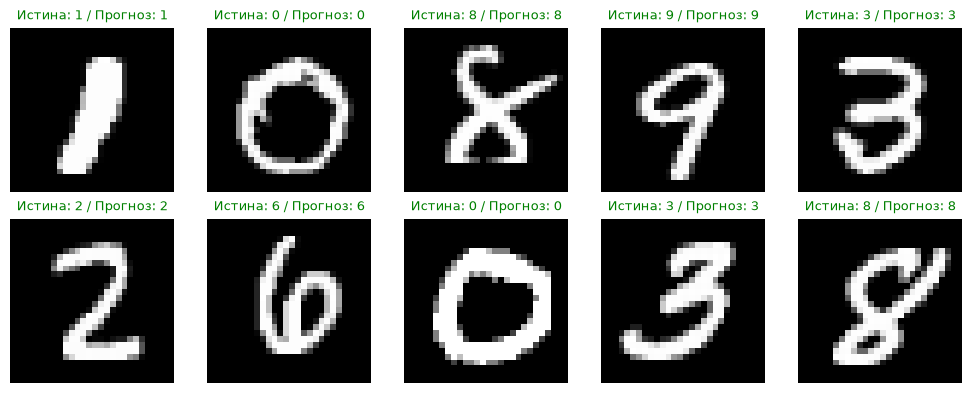

In [21]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
indices = rng.choice(len(X_test_images), size=10, replace=False)
for ax, index in zip(axes.ravel(), indices):
    correct = test_predictions[index] == y_test[index]
    ax.imshow(X_test_images[index], cmap="gray")
    ax.set_title(
        f"Истина: {y_test[index]} / Прогноз: {test_predictions[index]}",
        color="green" if correct else "red", fontsize=9
    )
    ax.axis("off")
plt.tight_layout()
plt.show()